# Task 3 — Feature Selection

**Saiket Systems | Machine Learning Internship**

Objective: assess relevant attributes for churn prediction. The task brief specifically highlights **Contract**, **MonthlyCharges**, and **tenure**. We compare that domain-informed shortlist with a Random Forest importance ranking.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root even if this notebook is opened from its own task folder.
HERE = Path.cwd().resolve()
ROOT = next((p for p in [HERE, *HERE.parents] if (p / "Dataset").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the Dataset folder. Open this notebook inside Saiket_ML_Internship.")
DATA_PATH = ROOT / "Dataset" / "Telco_Customer_Churn_Dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Dataset path: C:\Users\HP\Desktop\Saiket_ML_Internship\Dataset\Telco_Customer_Churn_Dataset.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Prepare the target and candidate features

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(r"^\\s*$", np.nan, regex=True), errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
y = df["Churn"].map({"No": 0, "Yes": 1})

# Core features explicitly suggested in the internship brief.
core_features = ["Contract", "MonthlyCharges", "tenure"]
X_core = pd.get_dummies(df[core_features], columns=["Contract"], drop_first=True, dtype=int)
print("Core feature matrix:", X_core.shape)
display(X_core.head())


Core feature matrix: (7043, 4)


,MonthlyCharges,tenure,Contract_One year,Contract_Two year
0,29.85,1,0,0
1,56.95,34,1,0
2,53.85,2,0,0
3,42.30,45,1,0
4,70.70,2,0,0


## 2. Compare churn patterns across core features

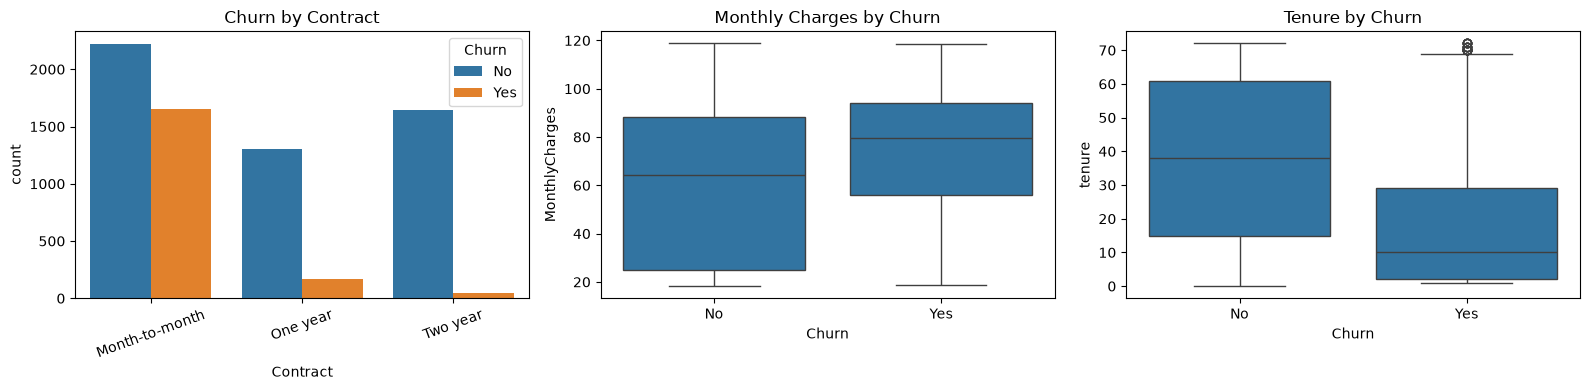

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Churn by Contract")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[2])
axes[2].set_title("Tenure by Churn")
plt.tight_layout()
plt.show()


## 3. Rank features using Random Forest importance

This is an exploratory ranking, not proof of causation. The full feature set is used to compare the domain shortlist with other candidate predictors.

,importance
TotalCharges,0.175876
tenure,0.164983
MonthlyCharges,0.152056
Contract_Two year,0.061353
InternetService_Fiber optic,0.041493
PaymentMethod_Electronic check,0.036130
Contract_One year,0.030233
OnlineSecurity_Yes,0.029039
gender_Male,0.025944
PaperlessBilling_Yes,0.024152


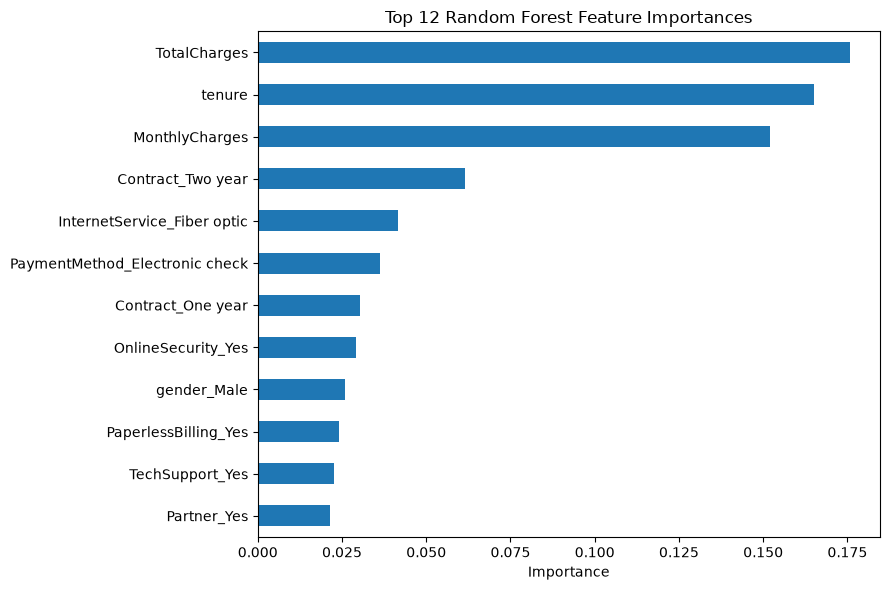

In [4]:
from sklearn.ensemble import RandomForestClassifier

X_all = pd.get_dummies(df.drop(columns=["Churn", "customerID"]), drop_first=True, dtype=int)
X_train_fs, X_test_fs, y_train_fs, y_test_fs = __import__("sklearn.model_selection", fromlist=["train_test_split"]).train_test_split(
    X_all, y, test_size=0.20, random_state=42, stratify=y
)
selector_model = RandomForestClassifier(n_estimators=250, random_state=42, class_weight="balanced", n_jobs=-1)
selector_model.fit(X_train_fs, y_train_fs)
importance = pd.Series(selector_model.feature_importances_, index=X_all.columns).sort_values(ascending=False)
display(importance.head(15).to_frame("importance"))
plt.figure(figsize=(9, 6))
importance.head(12).sort_values().plot(kind="barh")
plt.title("Top 12 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 4. Selected feature set and interpretation

In [5]:
print("Brief-recommended features:", core_features)
print("Top 10 ranked encoded features:")
display(importance.head(10).to_frame("importance"))
print("\\nInterpretation:")
print("- Contract type captures commitment length and is a useful retention signal.")
print("- Tenure captures how long a customer has stayed.")
print("- MonthlyCharges captures recurring cost differences.")
print("- Feature importance indicates predictive usefulness, not causality.")


Brief-recommended features: ['Contract', 'MonthlyCharges', 'tenure']
Top 10 ranked encoded features:


,importance
TotalCharges,0.175876
tenure,0.164983
MonthlyCharges,0.152056
Contract_Two year,0.061353
InternetService_Fiber optic,0.041493
PaymentMethod_Electronic check,0.036130
Contract_One year,0.030233
OnlineSecurity_Yes,0.029039
gender_Male,0.025944
PaperlessBilling_Yes,0.024152


\nInterpretation:
- Contract type captures commitment length and is a useful retention signal.
- Tenure captures how long a customer has stayed.
- MonthlyCharges captures recurring cost differences.
- Feature importance indicates predictive usefulness, not causality.
